# D2 — Variational autoencoders on MNIST

This notebook only **loads saved results** from `outputs/` (written by `run.py`) and makes the D2 figures:

1. ELBO curves (train and validation, mean ± SD over seeds)
2. Reconstructions of validation images
3. 2D latent space coloured by digit (model trained with `dim_latent: 2`)
4. Samples from the prior

All figures use the **validation set**; the test set is reserved for the final numbers on days 4–5.
Every figure is also written as one page of `figures/d2_vae.pdf`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.backends.backend_pdf import PdfPages

# repository root, whether the notebook runs from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.data import get_loaders
from src.models import build_model

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

torch.set_grad_enabled(False)   # analysis only: no gradients needed anywhere in this notebook

## Experiments

Map a label (shown in the figures) to an experiment folder in `outputs/`, i.e. the `name` field of its config.
Adjust these to your config names. The 2D latent scatter needs a separate model trained with `dim_latent: 2`.

In [2]:
experiments = {
    "VAE (d=2)": ROOT / "outputs" / "VAE_d2",
}
latent_2d_experiment = ROOT / "outputs" / "VAE_d2"

for label, p in {**experiments, "2D model": latent_2d_experiment}.items():
    n_seeds = len(list(p.glob("seed_*")))
    print(f"{label:10s} {p.name:20s} exists: {p.exists()!s:5s}  seeds: {n_seeds}")

VAE (d=2)  VAE_d2               exists: True   seeds: 3
2D model   VAE_d2               exists: True   seeds: 3


## Helpers

In [3]:
def seed_dirs(exp_dir):
    dirs = sorted(Path(exp_dir).glob("seed_*"))
    if not dirs:
        raise FileNotFoundError(f"no seed_* folders in {Path(exp_dir).resolve()}")
    return dirs


def load_histories(exp_dir):
    return [json.load(open(d / "history.json")) for d in seed_dirs(exp_dir)]


def mean_sd(histories, key, sign=1.0):
    """Mean and sample SD over seeds of one history entry, per epoch."""
    values = sign * np.array([h[key] for h in histories])          # (n_seeds, n_epochs)
    sd = values.std(axis=0, ddof=1) if len(values) > 1 else np.zeros(values.shape[1])
    return values.mean(axis=0), sd


def load_model(run_dir):
    """Rebuild a model from its saved config and load its trained weights."""
    cfg = yaml.safe_load(open(run_dir / "config.yaml"))
    model = build_model(cfg["model"])
    model.load_state_dict(torch.load(run_dir / "model.pt", map_location="cpu"))
    return model.eval(), cfg


def encode_latent(model, x):
    """Deterministic latent code: the encoder mean, passed through the flow if the model has one."""
    z = model.encoder(x)[:, 0]
    if hasattr(model, "IAF_flow"):
        z = model.IAF_flow(z)
    return z


def to_image(t):
    """(n, 1, 28, 28) tensor -> (n, 28, 28) numpy array for imshow."""
    return t.squeeze(1).cpu().numpy()


def clean_axes(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

## Data and PDF

The data settings (batch size, fixed 50,000 / 10,000 split) are read from the first run's saved config,
so the validation images are exactly those used during training.

In [4]:
first_run = seed_dirs(next(iter(experiments.values())))[0]
data_cfg = yaml.safe_load(open(first_run / "config.yaml"))["data"]
_, val_loader, _ = get_loaders(**data_cfg)        # the test loader is not used here
val_images, val_labels = next(iter(val_loader))

pdf = PdfPages(FIG_DIR / "d2_vae.pdf")

## 1. ELBO curves

Left: ELBO per image. The training curve is minus the epoch-average training loss, which equals the ELBO only for β = 1;
the validation curve is the β = 1 ELBO computed after each epoch, so it is comparable across models.
Right: the two parts of the validation loss, distortion D (reconstruction, −log p(x|z)) and rate R (KL).

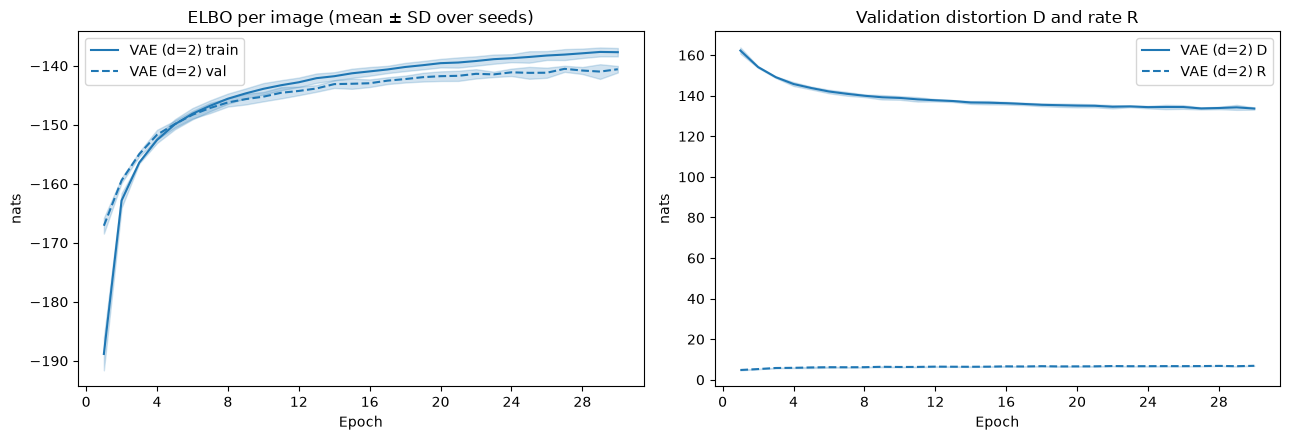

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for label, exp_dir in experiments.items():
    hs = load_histories(exp_dir)
    epochs = np.arange(1, len(hs[0]["train_loss"]) + 1)

    color = None
    for key, sign, style, name in [("train_loss", -1, "-", "train"), ("val_elbo", 1, "--", "val")]:
        m, s = mean_sd(hs, key, sign)
        line, = axes[0].plot(epochs, m, style, color=color, label=f"{label} {name}")
        color = line.get_color()                       # one colour per model
        axes[0].fill_between(epochs, m - s, m + s, color=color, alpha=0.2)

    for key, style, name in [("val_D", "-", "D"), ("val_R", "--", "R")]:
        m, s = mean_sd(hs, key)
        axes[1].plot(epochs, m, style, color=color, label=f"{label} {name}")
        axes[1].fill_between(epochs, m - s, m + s, color=color, alpha=0.2)

axes[0].set(title="ELBO per image (mean ± SD over seeds)", xlabel="Epoch", ylabel="nats")
axes[1].set(title="Validation distortion D and rate R", xlabel="Epoch", ylabel="nats")
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()

plt.tight_layout()
pdf.savefig(fig, bbox_inches="tight")
plt.show()

## 2. Reconstructions

Top row: validation images. Below: each model's reconstruction (first seed), decoded from the encoder mean,
so the pictures are deterministic. The decoder outputs Bernoulli probabilities, shown as grey values.

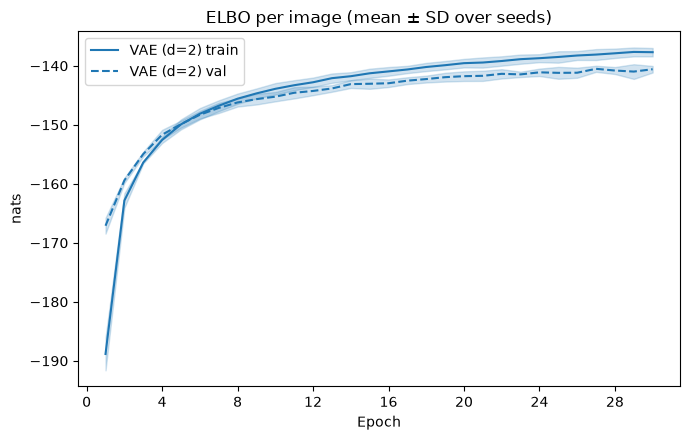

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for label, exp_dir in experiments.items():
    hs = load_histories(exp_dir)
    epochs = np.arange(1, len(hs[0]["train_loss"]) + 1)

    color = None
    for key, sign, style, name in [("train_loss", -1, "-", "train"), ("val_elbo", 1, "--", "val")]:
        m, s = mean_sd(hs, key, sign)
        line, = ax.plot(epochs, m, style, color=color, label=f"{label} {name}")
        color = line.get_color()                       # one colour per model
        ax.fill_between(epochs, m - s, m + s, color=color, alpha=0.2)

ax.set(title="ELBO per image (mean ± SD over seeds)", xlabel="Epoch", ylabel="nats")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()

plt.tight_layout()
pdf.savefig(fig, bbox_inches="tight")
plt.show()

## 3. 2D latent space (d = 2)

Latent codes (encoder means) of all validation images for the model trained with `dim_latent: 2`, coloured by digit.
The dashed circle (radius 2) marks where most of the prior N(0, I) lies; samples from the prior land mostly inside it.

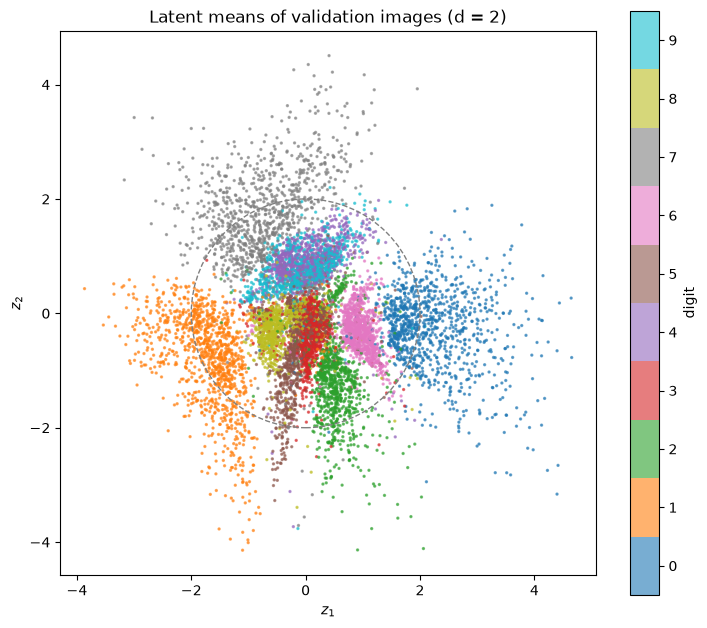

In [7]:
model_2d, _ = load_model(seed_dirs(latent_2d_experiment)[0])
assert model_2d.dim_latent == 2, f"expected a 2D model, got dim_latent = {model_2d.dim_latent}"

zs, ys = [], []
for images, labels in val_loader:
    zs.append(encode_latent(model_2d, images))
    ys.append(labels)
z = torch.cat(zs).numpy()
y = torch.cat(ys).numpy()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
sc = ax.scatter(z[:, 0], z[:, 1], c=y, cmap="tab10", vmin=-0.5, vmax=9.5, s=2, alpha=0.6)
fig.colorbar(sc, ax=ax, ticks=range(10), label="digit")
ax.add_patch(plt.Circle((0, 0), 2, fill=False, linestyle="--", color="gray"))
ax.set_aspect("equal")
ax.set(title="Latent means of validation images (d = 2)", xlabel="$z_1$", ylabel="$z_2$")

plt.tight_layout()
pdf.savefig(fig, bbox_inches="tight")
plt.show()

## 4. Samples from the prior

z ~ N(0, I), decoded directly (for a flow model too: the prior is defined on the flow's output space).
The same random z are used for every model with the same latent dimension, via a fixed generator seed.

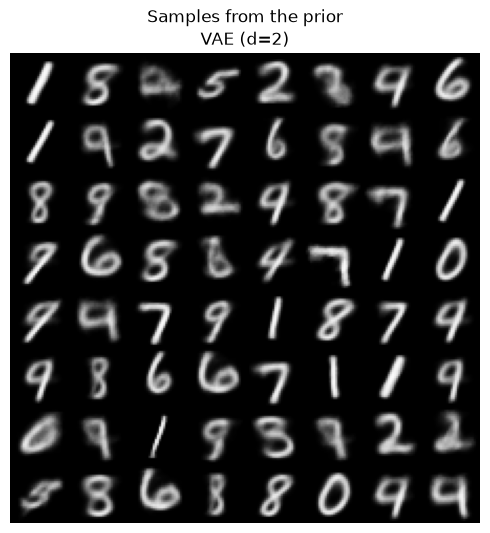

In [8]:
n_rows, n_cols = 8, 8
fig, axes = plt.subplots(1, len(experiments), figsize=(5 * len(experiments), 5.4))
axes = np.atleast_1d(axes)

for ax, (label, exp_dir) in zip(axes, experiments.items()):
    model, _ = load_model(seed_dirs(exp_dir)[0])
    gen = torch.Generator().manual_seed(0)
    z = torch.randn(n_rows * n_cols, model.dim_latent, generator=gen)
    imgs = to_image(model.decoder(z))
    canvas = imgs.reshape(n_rows, n_cols, 28, 28).transpose(0, 2, 1, 3).reshape(n_rows * 28, n_cols * 28)
    ax.imshow(canvas, cmap="gray", vmin=0, vmax=1)
    ax.set_title(label)
    ax.axis("off")

fig.suptitle("Samples from the prior")
plt.tight_layout()
pdf.savefig(fig, bbox_inches="tight")
plt.show()

## Save

In [9]:
pdf.close()
print("saved", FIG_DIR / "d2_vae.pdf")

saved /Users/Jeremie/Postdoc/representation_learning/vae_mnist/figures/d2_vae.pdf
